# M5 retail patterns: descriptive calibration for Kettlerock Value Stores

This notebook measures how retail sales behave in the M5 dataset: the weekly rhythm, the yearly rhythm, how far stores differ, how noisy and persistent weekly sales are, how many items sell nothing in a given week, how concentrated sales are in the best sellers, and how sales move around holidays.

Every result is a descriptive summary statistic. No model is fitted to M5, and no M5 value enters Kettlerock's data directly: each result becomes a parameter range in `calibrated_parameters.csv` and a row in `benchmark_sources.csv`, where it sits alongside figures from public filings and Canadian government data.

**Data:** M5 Forecasting competition data (Walmart unit sales for 3,049 products in 10 US stores, January 2011 to May 2016). Makridakis, S., Spiliotis, E. and Assimakopoulos, V. (2022), "M5 accuracy competition: Results, findings, and conclusions", *International Journal of Forecasting*, 38(4). The raw files are not stored in this repository; download `calendar.csv`, `sales_train_evaluation.csv` and `sell_prices.csv` from the Kaggle M5 Forecasting – Accuracy competition and place them in the same folder as this notebook.

## Setup

**Complete years only.** M5 starts on 29 January 2011 and ends on 22 May 2016. Measures built on whole years use 2012 to 2015, because the missing weeks of 2011 and the missing months of 2016 would otherwise distort the yearly pattern.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path(".")   # folder holding calendar.csv, sales_train_evaluation.csv and sell_prices.csv
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

CATS = ["FOODS", "HOUSEHOLD", "HOBBIES"]
FULL_YEARS = [2012, 2013, 2014, 2015]
pd.set_option("display.float_format", "{:.3f}".format)

## Loading the data

M5 stores one row per product per store and one column per day. Sales are whole units, so they are read as 16-bit integers: exact for these values, and about a quarter of the memory of the default type. Only `sales_train_evaluation.csv` is loaded, because it contains every day of the validation file plus the final 28 days. The price file is not used: Kettlerock's price response is authored, not estimated from Walmart prices.

In [2]:
cal = pd.read_csv(DATA / "calendar.csv", parse_dates=["date"])
day_cols = [f"d_{i}" for i in range(1, 1942)]
sales = pd.read_csv(
    DATA / "sales_train_evaluation.csv",
    dtype={c: "int16" for c in day_cols},
)
meta = sales[["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]]
units = sales[day_cols].to_numpy()          # rows: product-store, columns: days
cal = cal.iloc[: len(day_cols)].copy()       # calendar rows that have sales

print(f"{units.shape[0]:,} product-store series x {units.shape[1]:,} days")
print("Dates:", cal.date.min().date(), "to", cal.date.max().date())
print("Stores:", meta.store_id.nunique(), "| Products:", meta.item_id.nunique())
print(meta.groupby("cat_id").item_id.nunique())

30,490 product-store series x 1,941 days
Dates: 2011-01-29 to 2016-05-22
Stores: 10 | Products: 3049
cat_id
FOODS        1437
HOBBIES       565
HOUSEHOLD    1047
Name: item_id, dtype: int64


**Reading the output:** 30,490 product-store series over 1,941 days (29 January 2011 to 22 May 2016), covering 10 stores and 3,049 products in three categories. Food is the largest category by product count (1,437), followed by household (1,047) and hobbies (565).

## Checks before measuring

Three features of the data could quietly distort the measures if left untreated, so each is confirmed before any rule is set for it:

- **Christmas Day:** Walmart stores close.
- **Leading zeros:** a product's series is zero until the product is first stocked in that store.
- **SNAP payment days:** food sales in all three states rise on the days US food-assistance benefits are paid.

In [3]:
total_by_day = pd.Series(units.sum(axis=0), index=cal.date)
xmas = total_by_day[(total_by_day.index.month == 12) & (total_by_day.index.day == 25)]
print("Units sold on Christmas Day:", xmas.to_dict())
print("Median daily units:", int(total_by_day.median()))

first_sale = np.where(units.any(axis=1), (units > 0).argmax(axis=1), -1)
print(f"Series with a run of zeros before the first sale: {(first_sale > 0).mean():.1%}")
print("Series with no sales at all:", int((first_sale == -1).sum()))

is_xmas = ((cal.date.dt.month == 12) & (cal.date.dt.day == 25)).to_numpy()
for st in ["CA", "TX", "WI"]:
    rows_st = np.where((meta.cat_id == "FOODS") & (meta.state_id == st))[0]
    food_units = units[rows_st].sum(axis=0)
    snap = cal[f"snap_{st}"].to_numpy() == 1
    lift = food_units[snap & ~is_xmas].mean() / food_units[~snap & ~is_xmas].mean()
    print(f"{st}: food units on SNAP days relative to other days = {lift:.3f}")

Units sold on Christmas Day: {Timestamp('2011-12-25 00:00:00'): 13, Timestamp('2012-12-25 00:00:00'): 11, Timestamp('2013-12-25 00:00:00'): 20, Timestamp('2014-12-25 00:00:00'): 20, Timestamp('2015-12-25 00:00:00'): 14}
Median daily units: 33830


Series with a run of zeros before the first sale: 77.1%
Series with no sales at all: 0


CA: food units on SNAP days relative to other days = 1.098
TX: food units on SNAP days relative to other days = 1.152
WI: food units on SNAP days relative to other days = 1.295


**Reading the output and the rules that follow**

- **Christmas Day** records 11 to 20 units chain-wide against a median of about 34,000 a day: a closure, not a sales pattern. It is excluded from the daily measures (months and holidays). For the weekly measures (days of the week, noise and persistence), Christmas Day is filled in with the average of the same weekday one week before and one week after: the closure is not read as a collapse in demand, and no week goes missing from the 13-week moving average used for noise. Kettlerock is also closed on Christmas Day: Ontario, Quebec, Nova Scotia and New Brunswick require most retailers to close that day (Nova Scotia and New Brunswick also on Boxing Day), so Kettlerock's own closures come from provincial law rather than from M5. A check after the weekly-noise section compares this with dropping the Christmas weeks altogether.
- **Leading zeros** appear in 77% of series. They reflect products not yet on the shelf, so the zero-sales measure counts only weeks after a product's first sale in that store. Counting them would make intermittent demand look far worse than it is.
- **SNAP days** lift food sales by about 10% in California, 15% in Texas and 30% in Wisconsin. SNAP has no Canadian equivalent, so Kettlerock should not inherit it. Payments are concentrated around recurring parts of the month, so the effect largely washes out of the day-of-week measure, but it may still shape M5's food-category monthly pattern; M5 is therefore not used as the source of Kettlerock's overall monthly seasonality. In the short holiday windows it can create bumps near the start of a month, which is why the holiday results also report non-food categories on their own.

## Working tables

Daily units are summed by category (3 series) and by store and category (30 series). Weekly measures use Walmart's own weeks (`wm_yr_wk`, Saturday to Friday) and only weeks with all seven days, so a partial week at either end of the data is not mistaken for a drop in sales.

In [4]:
# daily units by category, and by store and category
cat_idx = {c: np.where(meta.cat_id == c)[0] for c in CATS}
daily_cat = pd.DataFrame({c: units[i].sum(axis=0) for c, i in cat_idx.items()}, index=cal.date)

store_cat = meta.store_id + "|" + meta.cat_id
daily_sc = pd.DataFrame(
    {k: units[np.where(store_cat == k)[0]].sum(axis=0) for k in sorted(store_cat.unique())},
    index=cal.date,
)

# complete Walmart weeks (Saturday to Friday)
week_id = cal.wm_yr_wk.to_numpy()
week_sizes = pd.Series(week_id).value_counts()
full_weeks = week_sizes[week_sizes == 7].index
week_has_xmas = pd.Series(is_xmas).groupby(week_id).any()
# Christmas Day filled in with the average of the same weekday one week before and one week after
def impute_xmas(frame):
    f = frame.astype(float).copy()
    pos = np.where(is_xmas)[0]
    f.iloc[pos] = (f.iloc[pos - 7].to_numpy() + f.iloc[pos + 7].to_numpy()) / 2
    return f

daily_cat_w = impute_xmas(daily_cat)     # for weekly measures
daily_sc_w = impute_xmas(daily_sc)
print(f"Complete weeks: {len(full_weeks)} | weeks containing Christmas Day: {int(week_has_xmas.sum())}")

Complete weeks: 277 | weeks containing Christmas Day: 5


**Reading the output:** 277 complete weeks, five of which contain Christmas Day. All 277 are used for the weekly measures, with Christmas Day filled in.

## 1. Day-of-week pattern

Each day's share of its week's sales, calculated within each complete week and then averaged over the 277 weeks, with Christmas Day filled in. Calculating shares inside each week gives every week an equal say; summing all Saturdays across five years would let the busier later years dominate. The standard deviation across weeks shows how much the pattern wobbles, which the generator needs as well as the average.

In [5]:
d = daily_cat_w.copy()
d["wk"] = week_id
d["weekday"] = cal.weekday.to_numpy()
keep = d.wk.isin(full_weeks)
d = d[keep]

order = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
rows = []
for c in CATS:
    share = d[c] / d.groupby("wk")[c].transform("sum")
    s = share.groupby(d.weekday).agg(["mean", "std"]).reindex(order)
    s["category"] = c
    rows.append(s.reset_index())
dow = pd.concat(rows).rename(columns={"mean": "share_of_week", "std": "std_across_weeks"})
dow.to_csv(OUT / "m5_dow_shares.csv", index=False)
dow.pivot(index="weekday", columns="category", values="share_of_week").reindex(order)

category,FOODS,HOBBIES,HOUSEHOLD
weekday,,,
Saturday,0.170,0.176,0.180
Sunday,0.172,0.159,0.174
Monday,0.137,0.133,0.134
Tuesday,0.127,0.127,0.123
Wednesday,0.126,0.129,0.121
Thursday,0.126,0.129,0.123
Friday,0.141,0.149,0.145


**How to read the table:** each column sums to 1. A value of 0.170 means that day carries 17.0% of the week's units; an even split would be 1/7, or 0.143. In all three categories Saturday and Sunday carry about 16% to 18% each, Tuesday to Thursday about 12% to 13% each, and Friday about 14% to 15%. A weekend day sells roughly 1.4 times a mid-week day.

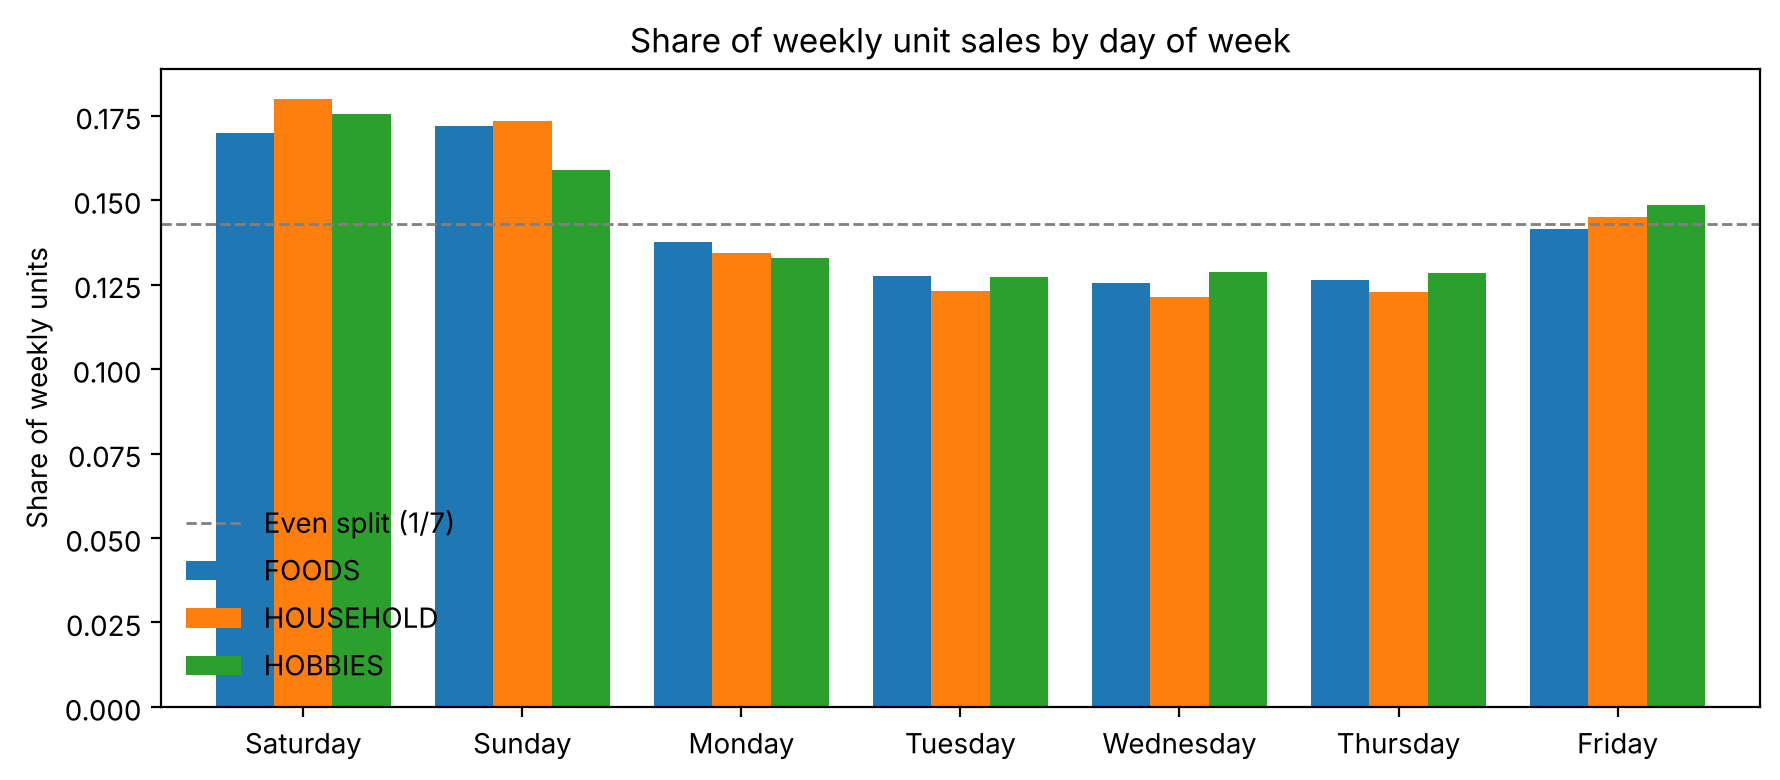

In [6]:
piv = dow.pivot(index="weekday", columns="category", values="share_of_week").reindex(order)
ax = piv[CATS].plot.bar(figsize=(9, 4), rot=0, width=0.8)
ax.axhline(1 / 7, color="grey", lw=1, ls="--", label="Even split (1/7)")
ax.set_ylabel("Share of weekly units"); ax.set_xlabel(""); ax.legend(frameon=False)
ax.set_title("Share of weekly unit sales by day of week")
plt.tight_layout(); plt.show()

## 2. Month-of-year pattern

For each category and year, average daily sales in each month are divided by average daily sales for the whole year (total units divided by the number of days counted). Daily averages remove the effect of months having 28 to 31 days, and dividing by the same year's average removes growth between years, leaving only the shape within a year. The minimum and maximum columns show how stable that shape is from year to year. Christmas Day is excluded.

In [7]:
d = daily_cat[~is_xmas].copy()
d["year"], d["month"] = d.index.year, d.index.month
d = d[d.year.isin(FULL_YEARS)]

rows = []
for c in CATS:
    m = d.groupby(["year", "month"])[c].mean()
    year_avg = d.groupby("year")[c].mean()                       # total units / days in the year
    idx = m / year_avg.reindex(m.index.get_level_values("year")).to_numpy()
    t = idx.groupby(level="month").agg(["mean", "min", "max"])
    t["category"] = c
    rows.append(t.reset_index())
month_idx = pd.concat(rows).rename(columns={"mean": "index_mean", "min": "index_min", "max": "index_max"})
month_idx.to_csv(OUT / "m5_month_index.csv", index=False)
month_idx.pivot(index="month", columns="category", values="index_mean")[CATS]

category,FOODS,HOUSEHOLD,HOBBIES
month,,,
1,0.936,0.831,0.920
2,0.972,0.984,1.009
3,0.976,0.988,0.995
4,0.971,0.962,1.011
5,0.978,0.948,0.993
6,1.056,1.025,1.063
7,1.052,1.034,1.003
8,1.071,1.107,0.981
9,1.049,1.102,0.957


**How to read the table:** 1.000 is an average month. A value of 1.071 means daily sales that month run 7.1% above the year's average day; 0.831 means 16.9% below. Food peaks in summer (June to September, up to 1.071) and is lowest in January (0.936). Household is strongest in August and September (about 1.10) and weakest in January (0.831). Hobbies is the flattest, with small peaks in June and December.

There is **no December peak** in any category. M5 is a grocery-heavy supercentre with no seasonal-merchandise department, unlike a value retailer whose December is its biggest month. M5 therefore informs how Kettlerock's categories differ from one another across the year, while the overall monthly shape comes from Statistics Canada retail sales and Dollarama's quarterly results.

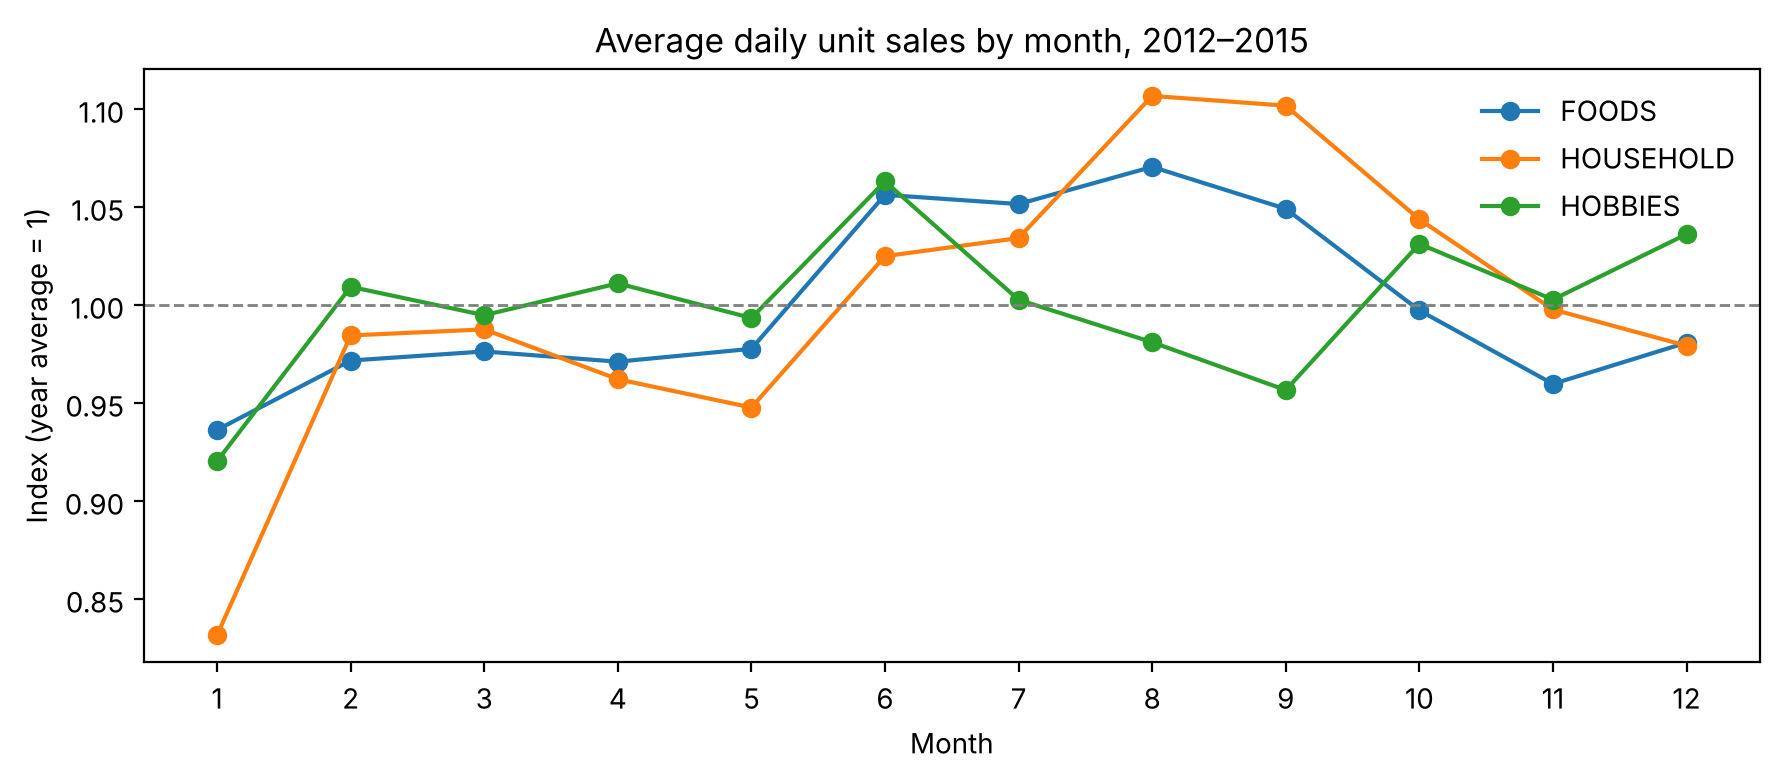

In [8]:
piv = month_idx.pivot(index="month", columns="category", values="index_mean")[CATS]
ax = piv.plot(figsize=(9, 4), marker="o")
ax.axhline(1, color="grey", lw=1, ls="--")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Month"); ax.set_ylabel("Index (year average = 1)")
ax.set_title("Average daily unit sales by month, 2012–2015"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Differences between stores

Each store's annual units relative to the 10-store average for that year, and the coefficient of variation (standard deviation divided by mean) across stores. Ratios to the average are used rather than unit totals because Kettlerock's stores are scaled to its own sales level: what transfers is the spread, not Walmart's volume. The spread is also measured by category, because a store can be strong in one category and weak in another.

In [9]:
d = daily_sc.copy()
d["year"] = d.index.year
annual = d[d.year.isin(FULL_YEARS)].groupby("year").sum().T
annual.index = pd.MultiIndex.from_tuples([k.split("|") for k in annual.index], names=["store", "category"])

total = annual.groupby(level="store").sum()
ratio = total / total.mean()
store_spread = pd.DataFrame({
    "ratio_to_mean_avg": ratio.mean(axis=1),
    "ratio_min_year": ratio.min(axis=1),
    "ratio_max_year": ratio.max(axis=1),
}).sort_values("ratio_to_mean_avg")
store_spread.to_csv(OUT / "m5_store_ratios.csv")

cv = {"ALL": (total.std() / total.mean())}
for c in CATS:
    x = annual.xs(c, level="category")
    cv[c] = x.std() / x.mean()
store_cv = pd.DataFrame(cv)
store_cv.to_csv(OUT / "m5_store_cv.csv")
display(store_spread); store_cv

,ratio_to_mean_avg,ratio_min_year,ratio_max_year
store,,,
CA_4,0.628,0.605,0.646
WI_1,0.796,0.601,0.924
CA_2,0.839,0.772,0.876
TX_1,0.851,0.834,0.882
TX_3,0.921,0.865,0.973
WI_3,0.944,0.805,1.192
WI_2,1.030,0.845,1.116
TX_2,1.097,0.989,1.211
CA_1,1.177,1.164,1.205


,ALL,FOODS,HOUSEHOLD,HOBBIES
year,,,,
2012,0.340,0.366,0.356,0.292
2013,0.304,0.303,0.382,0.316
2014,0.317,0.318,0.380,0.331
2015,0.271,0.264,0.347,0.305


**How to read the tables:** in the first table, 1.00 is an average store; the weakest store sells about 0.63 times the average and the strongest about 1.72 times, with one store (CA_3) well above the rest. The minimum and maximum columns show how much each store's position moved between 2012 and 2015. In the second table, a coefficient of variation of about 0.31 means the standard deviation of annual store sales is about 31% of the mean; household generally varies most between stores (about 0.35 to 0.38). With only 10 stores, this is a starting range for Kettlerock's store level factor rather than a precise estimate.

## 4. Week-to-week noise and persistence

For each store and category, weekly sales are compared with a 13-week centred moving average. Thirteen weeks is a quarter: long enough to follow the trend and the slower seasonal swings, short enough not to absorb week-to-week movement, and centring keeps it from lagging behind turning points. What remains is short-term movement, measured in logs so that a 5% swing counts the same in a large and a small store.

- **Noise:** the standard deviation of that remaining movement.
- **Persistence:** its correlation with the previous week (lag-1 autocorrelation), meaning how far a good or bad week carries into the next.

Weekly totals are built with Christmas Day filled in, so no week is missing and a closed day does not pull down the moving average of the weeks around it.

In [10]:
w = daily_sc_w.copy()
w["wk"] = week_id
weekly = w[w.wk.isin(full_weeks)].groupby("wk").sum()

rows = []
for k in weekly.columns:
    y = weekly[k].astype(float)
    ma = y.rolling(13, center=True).mean()
    dev = np.log(y / ma)
    dev = dev.dropna()
    store, cat = k.split("|")
    rows.append({"store": store, "category": cat, "noise_sd": dev.std(),
                 "lag1_autocorr": dev.autocorr(1), "weeks": len(dev)})
noise = pd.DataFrame(rows)
noise.to_csv(OUT / "m5_weekly_noise.csv", index=False)
noise.groupby("category")[["noise_sd", "lag1_autocorr"]].describe(percentiles=[0.1, 0.5, 0.9]).T

category             FOODS  HOBBIES  HOUSEHOLD
noise_sd      count 10.000   10.000     10.000
              mean   0.084    0.082      0.065
              std    0.034    0.011      0.021
              min    0.050    0.065      0.039
              10%    0.059    0.070      0.046
              50%    0.073    0.081      0.064
              90%    0.132    0.097      0.087
              max    0.162    0.100      0.109
lag1_autocorr count 10.000   10.000     10.000
              mean   0.188    0.152      0.210
              std    0.085    0.056      0.131
              min    0.065    0.056     -0.071
              10%    0.124    0.085      0.093
              50%    0.156    0.157      0.243
              90%    0.307    0.208      0.339
              max    0.350    0.219      0.366

**How to read the table:** the typical week deviates about 7.5% from its trend (median noise across the 30 series 0.075; household is calmer at 0.064). Persistence has a median of 0.16: a week 10% above trend is followed, on average, by a week only about 1.6% above trend. Weekly sales are therefore mostly fresh noise each week with a small carry-over, which sets the generator's noise and drift settings.

### Check: filling in Christmas Day versus dropping Christmas weeks

The alternative treatment is to drop the five Christmas weeks. The measures are recalculated that way to show how much the choice matters. Dropping has a drawback for noise and persistence: the Christmas week is removed only after the moving average is built, so its low total still pulls down the moving average of the six weeks either side and distorts their deviations.

In [11]:
# day of week, all categories pooled: Christmas Day filled in versus Christmas weeks dropped
def dow_pooled(daily, drop_xmas_weeks):
    d = daily.sum(axis=1).to_frame("units")
    d["wk"], d["weekday"] = week_id, cal.weekday.to_numpy()
    keep = d.wk.isin(full_weeks)
    if drop_xmas_weeks:
        keep &= ~d.wk.map(week_has_xmas)
    d = d[keep]
    return (d.units / d.groupby("wk").units.transform("sum")).groupby(d.weekday).mean().reindex(order)

dow_check = pd.DataFrame({
    "christmas_day_filled_in": dow_pooled(daily_cat_w[CATS], False),
    "christmas_weeks_dropped": dow_pooled(daily_cat[CATS], True),
})
dow_check["difference"] = dow_check.christmas_weeks_dropped - dow_check.christmas_day_filled_in

# weekly noise and persistence: the same comparison
def noise_stats(daily, drop_xmas_weeks):
    w = daily.copy(); w["wk"] = week_id
    wkly = w[w.wk.isin(full_weeks)].groupby("wk").sum()
    xw = week_has_xmas.reindex(wkly.index).to_numpy()
    sd, ac = [], []
    for k in wkly.columns:
        y = wkly[k].astype(float)
        dev = np.log(y / y.rolling(13, center=True).mean())
        if drop_xmas_weeks:
            dev[xw] = np.nan
        dev = dev.dropna()
        sd.append(dev.std()); ac.append(dev.autocorr(1))
    return np.median(sd), np.median(ac)

noise_check = pd.DataFrame(
    [noise_stats(daily_sc_w, False), noise_stats(daily_sc, True)],
    index=["christmas_day_filled_in", "christmas_weeks_dropped"],
    columns=["noise_sd_median", "lag1_autocorr_median"],
)
display(dow_check); noise_check

,christmas_day_filled_in,christmas_weeks_dropped,difference
weekday,,,
Saturday,0.173,0.173,0.000
Sunday,0.171,0.171,0.000
Monday,0.136,0.136,-0.000
Tuesday,0.126,0.126,-0.000
Wednesday,0.125,0.125,-0.000
Thursday,0.126,0.126,-0.000
Friday,0.143,0.143,-0.000


,noise_sd_median,lag1_autocorr_median
christmas_day_filled_in,0.075,0.160
christmas_weeks_dropped,0.075,0.143


**How to read the output:** the day-of-week shares agree to the third decimal place under both treatments, and weekly noise is 0.075 either way. Persistence differs: 0.160 with Christmas Day filled in, 0.143 with Christmas weeks dropped. The lower figure comes from the distortion described above, so the filled-in value, 0.160, is the one carried into calibration.

## 5. Items that sell nothing, and concentration of sales

**Zero-sales weeks:** the share of product-store weeks with no units sold, counted only after the product's first sale in that store. The spread across products (10th, 50th and 90th percentiles) is reported as well as the average, because some products almost always sell while others sit unsold for long stretches.

**Concentration:** the share of each category's units sold by its top 10% and top 20% of products across all 10 stores in 2015, the latest complete year, when nearly every product had launched. Units are used rather than revenue because Kettlerock's item baseline is built in units before prices are applied.

In [12]:
fw = np.array(sorted(full_weeks))
week_pos = pd.Series(range(len(fw)), index=fw)
col_week = pd.Series(week_id).map(week_pos).to_numpy()
valid = ~np.isnan(col_week)
n_w = len(fw)

wk_units = np.zeros((units.shape[0], n_w), dtype=np.int32)
for j in np.where(valid)[0]:
    wk_units[:, int(col_week[j])] += units[:, j]

first_wk = np.full(units.shape[0], n_w)
has_sale = first_sale >= 0
first_wk[has_sale] = pd.Series(week_id[first_sale[has_sale]]).map(week_pos).fillna(0).to_numpy().astype(int)
after_first = np.arange(n_w)[None, :] >= first_wk[:, None]
zero = (wk_units == 0) & after_first

rows = []
for c in CATS:
    i = cat_idx[c]
    per_series = zero[i].sum(axis=1) / np.maximum(after_first[i].sum(axis=1), 1)
    rows.append({"category": c,
                 "zero_week_share": zero[i].sum() / after_first[i].sum(),
                 "series_median": np.median(per_series[has_sale[i]]),
                 "series_p10": np.percentile(per_series[has_sale[i]], 10),
                 "series_p90": np.percentile(per_series[has_sale[i]], 90)})
intermittency = pd.DataFrame(rows)
intermittency.to_csv(OUT / "m5_intermittency.csv", index=False)
intermittency

,category,zero_week_share,series_median,series_p10,series_p90
0,FOODS,0.200,0.166,0.015,0.451
1,HOUSEHOLD,0.260,0.209,0.018,0.566
2,HOBBIES,0.295,0.272,0.043,0.603


**How to read the table:** 20% of food product-weeks, 26% of household and 30% of hobbies record no sales. The typical product (median) is close to those levels, but the range is wide: the best-selling 10% of products almost never miss a week, while the slowest 10% miss about half of them or more. M5 stores carry about 3,000 products; Kettlerock carries 180, each selling more often, so these values are an upper bound on Kettlerock's zero-sales weeks rather than a target.

In [13]:
y2015 = (cal.year == 2015).to_numpy()
item_units = pd.DataFrame({"item_id": meta.item_id, "cat_id": meta.cat_id,
                           "units": units[:, y2015].sum(axis=1)})
item_units = item_units.groupby(["cat_id", "item_id"]).units.sum()

rows, lorenz = [], {}
for c in CATS:
    u = item_units.loc[c].sort_values(ascending=False).to_numpy()
    cum = np.cumsum(u) / u.sum()
    n = len(u)
    rows.append({"category": c, "products": n,
                 "top10pct_share": cum[int(np.ceil(0.1 * n)) - 1],
                 "top20pct_share": cum[int(np.ceil(0.2 * n)) - 1],
                 "products_with_zero_units_2015": int((u == 0).sum())})
    lorenz[c] = (np.arange(1, n + 1) / n, cum)
concentration = pd.DataFrame(rows)
concentration.to_csv(OUT / "m5_concentration.csv", index=False)
concentration

,category,products,top10pct_share,top20pct_share,products_with_zero_units_2015
0,FOODS,1437,0.459,0.617,0
1,HOUSEHOLD,1047,0.457,0.622,1
2,HOBBIES,565,0.485,0.631,1


**How to read the table:** in every category the top 20% of products sell about 62% to 63% of units, and the top 10% about 46% to 49%. Sales are concentrated, though less sharply than the 80/20 rule of thumb. This shapes how Kettlerock's item baseline shares are spread across its 180 items.

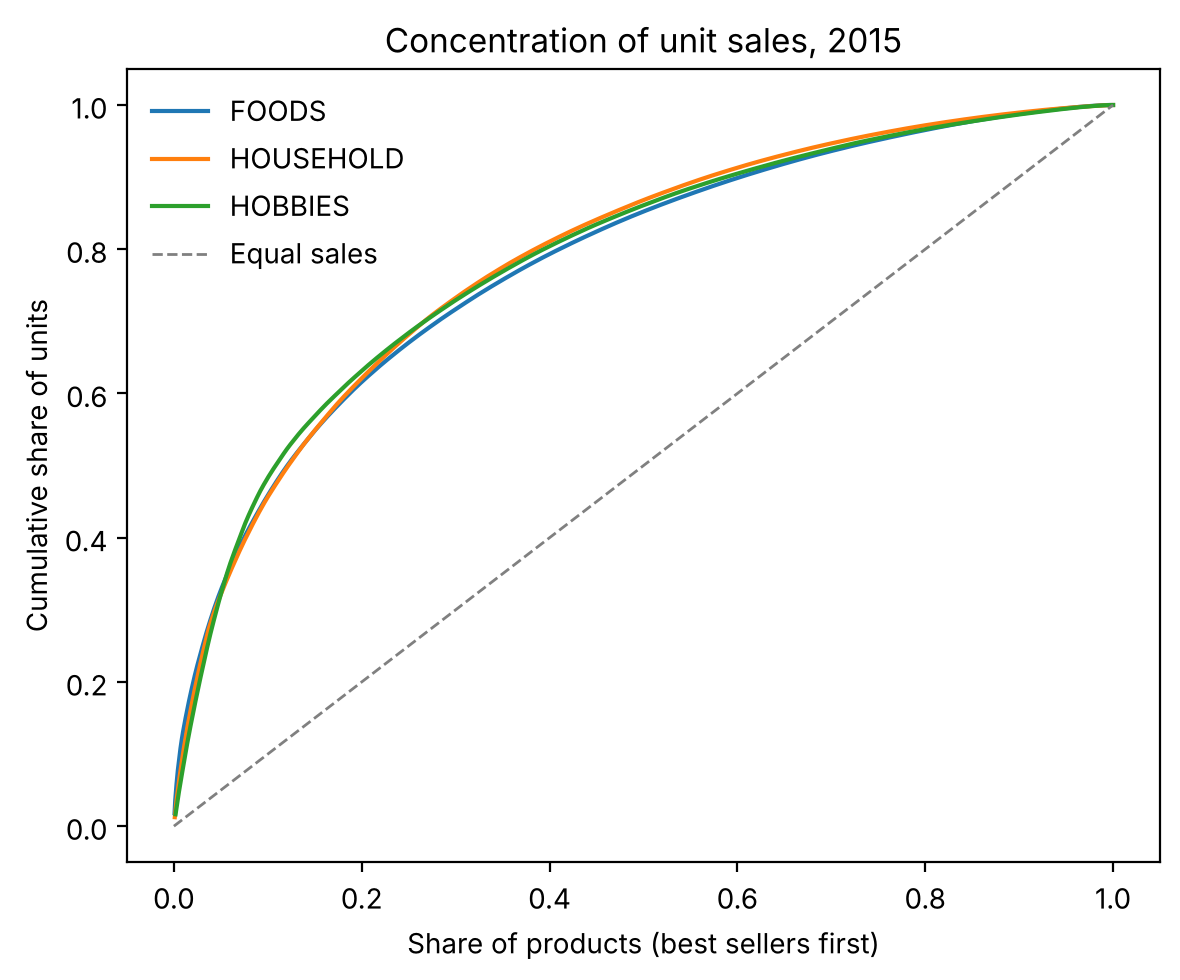

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
for c in CATS:
    x, y = lorenz[c]
    ax.plot(x, y, label=c)
ax.plot([0, 1], [0, 1], color="grey", lw=1, ls="--", label="Equal sales")
ax.set_xlabel("Share of products (best sellers first)"); ax.set_ylabel("Cumulative share of units")
ax.set_title("Concentration of unit sales, 2015"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**How to read the chart:** the further a curve bows above the dashed diagonal, the more sales depend on a few best sellers. The three categories nearly overlap, so concentration is similar across them.

## 6. Sales around holidays (descriptive)

For each of nine US holidays, every day from 14 days before to 3 days after is compared with a baseline, and the ratios are averaged over every year with a complete window.

- **Baseline:** the average of the same weekday in the four weeks starting six weeks before the holiday.
- **Same weekday:** removes the day-of-week pattern; otherwise a holiday falling on a Saturday would look like a lift.
- **Taken from before the window:** keeps the holiday build-up out of the baseline.
- **Other listed events excluded:** stops, for example, Thanksgiving from inflating the Christmas baseline.
- **Non-food reported separately:** food is affected by SNAP payment timing near the start of each month.

These are US holidays at Walmart. Their shapes are mapped to Kettlerock's Canadian calendar by an authored relationship, and the size of Kettlerock's holiday lifts is authored.

In [15]:
EVENTS = ["Christmas", "Thanksgiving", "Halloween", "Easter", "ValentinesDay",
          "Mother's day", "NewYear", "IndependenceDay", "LaborDay"]
dates = cal.date.reset_index(drop=True)
daily_all = daily_cat.copy()
daily_all["ALL"] = daily_all[CATS].sum(axis=1)
daily_all["NONFOOD"] = daily_all[["HOUSEHOLD", "HOBBIES"]].sum(axis=1)
vals = daily_all.reset_index(drop=True)
vals.loc[is_xmas, :] = np.nan
event_day = (cal.event_name_1.notna() | cal.event_name_2.notna()).to_numpy()
base_vals = vals.copy()
base_vals.loc[event_day, :] = np.nan                        # keep other holidays out of the baseline

ev = pd.concat([cal[["date", "event_name_1"]].rename(columns={"event_name_1": "event"}),
                cal[["date", "event_name_2"]].rename(columns={"event_name_2": "event"})]).dropna()
rows = []
for name in EVENTS:
    for edate in ev.loc[ev.event == name, "date"]:
        e = int(dates[dates == edate].index[0])
        if e - 42 < 0 or e + 3 >= len(dates):
            continue
        base_days = [e - 42 + 7 * k for k in range(4)]          # same weekday, 6 to 3 weeks before
        for off in range(-14, 4):
            day = e + off
            same_wd = [b + (off % 7) for b in base_days]
            base = base_vals.loc[same_wd].mean()
            r = vals.loc[day] / base
            rows.append({"event": name, "year": edate.year, "offset": off, **r.to_dict()})
hol = pd.DataFrame(rows)
hol_avg = hol.groupby(["event", "offset"])[CATS + ["ALL", "NONFOOD"]].mean()
hol_avg.to_csv(OUT / "m5_holiday_windows.csv")

summary = []
for name in EVENTS:
    t = hol_avg.loc[name, "ALL"]
    n = hol_avg.loc[name, "NONFOOD"]
    summary.append({"event": name, "years": hol[hol.event == name].year.nunique(),
                    "ratio_on_day": t.loc[0], "peak_ratio": t.max(), "peak_offset_days": int(t.idxmax()),
                    "lowest_ratio": t.min(), "lowest_offset_days": int(t.idxmin()),
                    "nonfood_peak_ratio": n.max(), "nonfood_peak_offset_days": int(n.idxmax())})
holiday_summary = pd.DataFrame(summary)
holiday_summary.to_csv(OUT / "m5_holiday_summary.csv", index=False)
holiday_summary

,event,years,ratio_on_day,peak_ratio,peak_offset_days,lowest_ratio,lowest_offset_days,nonfood_peak_ratio,nonfood_peak_offset_days
0,Christmas,5,NaN,1.119,-2,0.917,2,1.165,1
1,Thanksgiving,5,0.717,1.257,-1,0.717,0,1.144,-1
2,Halloween,5,0.858,1.101,3,0.858,0,1.129,1
3,Easter,6,0.845,1.129,-2,0.845,0,1.063,3
4,ValentinesDay,5,1.000,1.240,-2,1.000,0,1.242,-2
5,Mother's day,6,0.843,1.098,1,0.843,0,1.050,-9
6,NewYear,5,0.824,1.135,1,0.824,0,1.204,1
7,IndependenceDay,5,1.031,1.319,-1,0.925,-5,1.222,-1
8,LaborDay,5,1.248,1.248,0,0.915,-11,1.213,0


**How to read the table:** a ratio of 1.25 means sales that day ran 25% above a normal day of the same weekday; an offset of −2 means two days before the holiday. Lifts are modest, about 1.1 to 1.3 times normal, and usually peak one or two days before the holiday. Several holidays dip on the day itself (Thanksgiving to 0.72, Easter to 0.85), when many shoppers stay home. Some peaks fall at the start of a month, such as Halloween at +3 days (3 November); without food, the peak moves to +1 day (1 November), so part of the all-category bump is month-start food spending rather than the holiday. Christmas Day itself shows no value because the stores are closed.

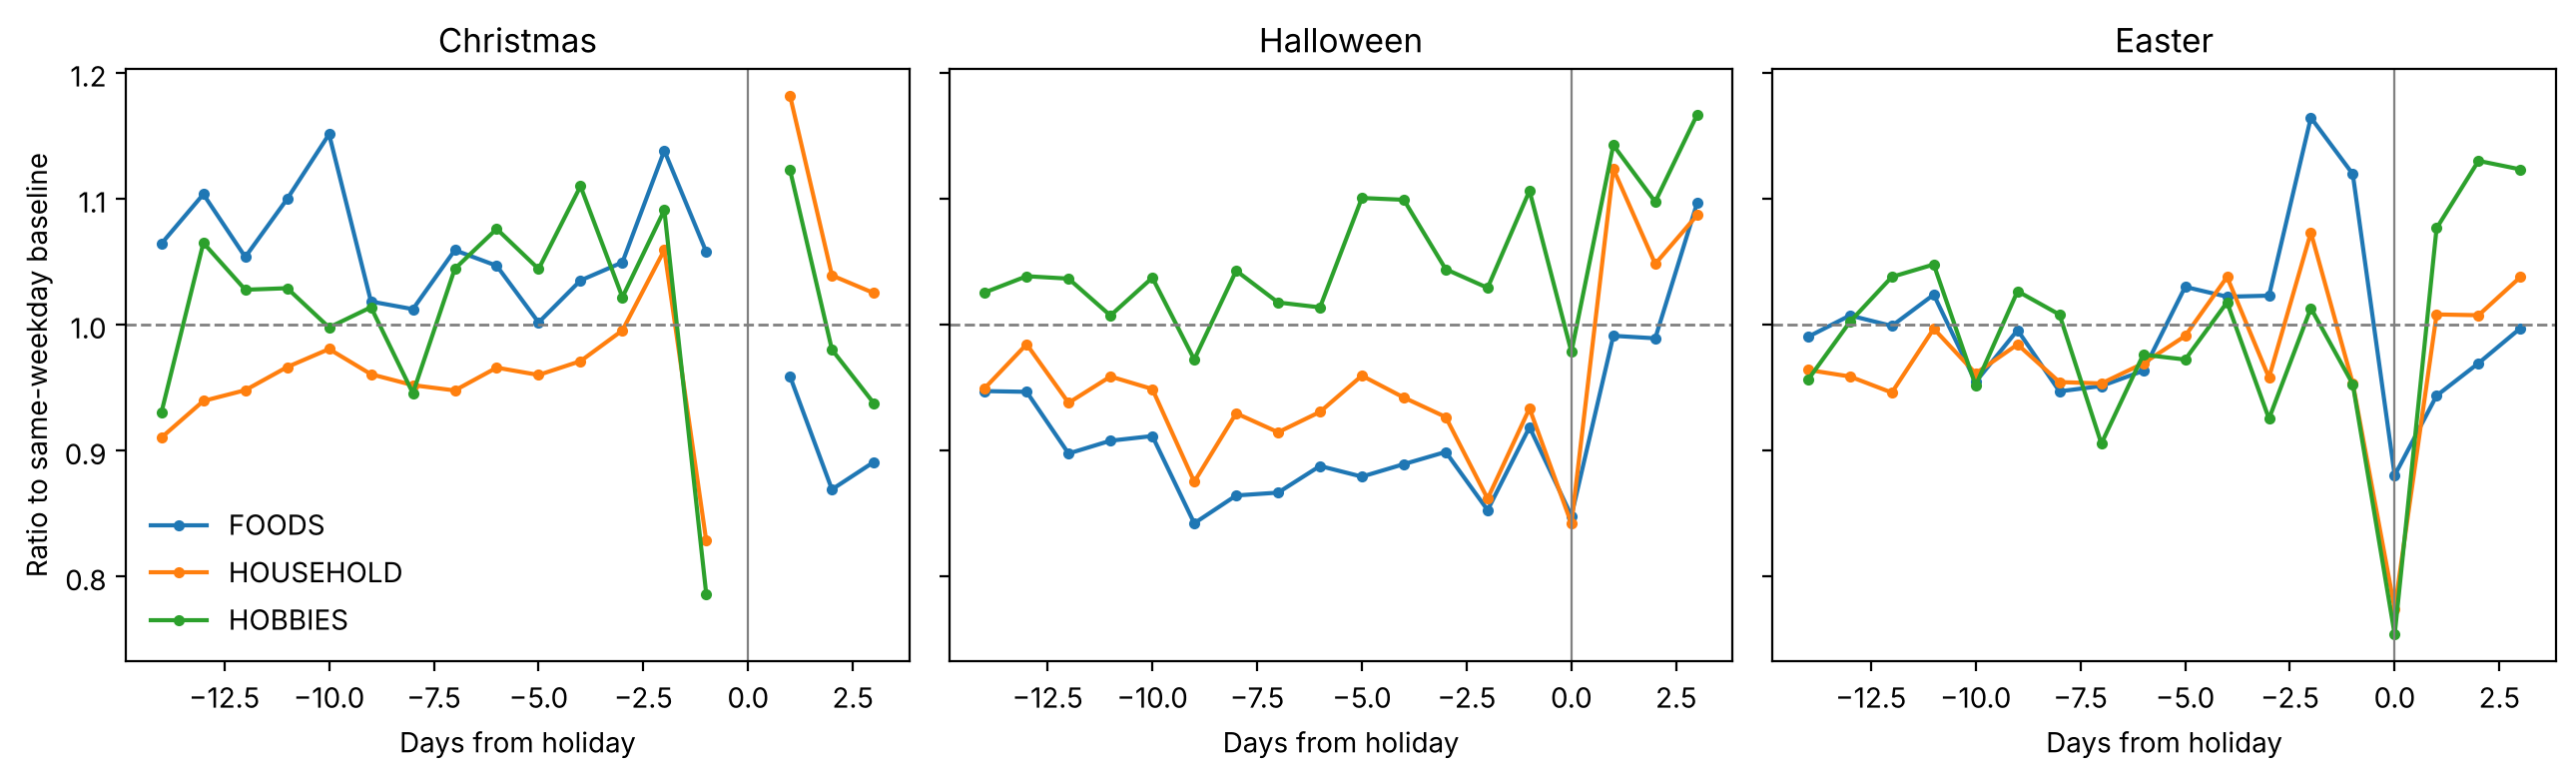

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, ["Christmas", "Halloween", "Easter"]):
    t = hol_avg.loc[name]
    for c in CATS:
        ax.plot(t.index, t[c], marker=".", label=c)
    ax.axhline(1, color="grey", lw=1, ls="--"); ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(name); ax.set_xlabel("Days from holiday")
axes[0].set_ylabel("Ratio to same-weekday baseline"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**How to read the chart:** each line is a category's daily ratio to its baseline; the dashed line at 1 is a normal day, and the vertical line marks the holiday. The Christmas build-up is gentle, food runs below baseline through late October and then jumps on 1 November, and Easter shows a clear pre-holiday peak followed by a dip on the day.

## Summary statistics carried into calibration

The headline value of each measure, written to `outputs/m5_summary.csv`. Each row becomes an M5 row in `benchmark_sources.csv`.

The all-category day-of-week and monthly figures **pool the units of all three categories** before calculating, so each category counts in proportion to its unit sales. A simple average of the three categories would give hobbies, the smallest category, as much weight as food, the largest. The per-category values remain in the detailed output files.

In [17]:
# all categories pooled: shares and indexes computed on total units, so each category counts by its unit volume
d = daily_cat_w[CATS].sum(axis=1).to_frame("units")
d["wk"], d["weekday"] = week_id, cal.weekday.to_numpy()
d = d[d.wk.isin(full_weeks)]
dow_all = (d.units / d.groupby("wk").units.transform("sum")).groupby(d.weekday).mean().reindex(order)

m = daily_cat[CATS].sum(axis=1)[~is_xmas]
m = m[m.index.year.isin(FULL_YEARS)]
mm = m.groupby([m.index.year, m.index.month]).mean()
year_avg = m.groupby(m.index.year).mean()                    # total units / days in the year
mi = (mm / year_avg.reindex(mm.index.get_level_values(0)).to_numpy()).groupby(level=1).mean()
rows = [
    ("Day-of-week share, highest day (all categories pooled)", f"{dow_all.idxmax()} {dow_all.max():.3f}", "share of week"),
    ("Day-of-week share, lowest day (all categories pooled)", f"{dow_all.idxmin()} {dow_all.min():.3f}", "share of week"),
    ("Month index range (all categories pooled)", f"{mi.min():.3f} to {mi.max():.3f}", "index, year average = 1"),
    ("Store sales ratio to mean, lowest to highest", f"{store_spread.ratio_to_mean_avg.min():.2f} to {store_spread.ratio_to_mean_avg.max():.2f}", "ratio"),
    ("Store coefficient of variation, all categories", f"{store_cv['ALL'].mean():.3f}", "ratio"),
    ("Weekly noise SD, median store-category", f"{noise.noise_sd.median():.3f}", "log deviation"),
    ("Weekly lag-1 autocorrelation, median store-category", f"{noise.lag1_autocorr.median():.3f}", "correlation"),
]
for _, r in intermittency.iterrows():
    rows.append((f"Zero-sales week share, {r.category}", f"{r.zero_week_share:.3f}", "share of product-store weeks"))
for _, r in concentration.iterrows():
    rows.append((f"Top 20% of products' share of units, {r.category}", f"{r.top20pct_share:.3f}", "share of units"))
for _, r in holiday_summary.iterrows():
    rows.append((f"{r.event}: peak ratio and day (all / non-food)", f"{r.peak_ratio:.2f} at {r.peak_offset_days:+d} days / {r.nonfood_peak_ratio:.2f} at {r.nonfood_peak_offset_days:+d} days", "ratio to baseline"))
m5_summary = pd.DataFrame(rows, columns=["metric", "value", "unit"])
m5_summary.to_csv(OUT / "m5_summary.csv", index=False)
m5_summary

,metric,value,unit
0,"Day-of-week share, highest day (all categories...",Saturday 0.173,share of week
1,"Day-of-week share, lowest day (all categories ...",Wednesday 0.125,share of week
2,Month index range (all categories pooled),0.911 to 1.071,"index, year average = 1"
3,"Store sales ratio to mean, lowest to highest",0.63 to 1.72,ratio
4,"Store coefficient of variation, all categories",0.308,ratio
5,"Weekly noise SD, median store-category",0.075,log deviation
6,"Weekly lag-1 autocorrelation, median store-cat...",0.160,correlation
7,"Zero-sales week share, FOODS",0.200,share of product-store weeks
8,"Zero-sales week share, HOUSEHOLD",0.260,share of product-store weeks
9,"Zero-sales week share, HOBBIES",0.295,share of product-store weeks


## Limits of these measures

- M5 records **units sold**, not transactions, so these patterns describe sales activity. Kettlerock's transaction counts are calibrated from public filings, with an authored link between units and transactions.
- The stores are **10 US Walmart supercentres** in three states, not dollar stores, and M5 has **no seasonal merchandise category**. Holiday shapes describe general demand, not seasonal-goods sell-through, and the monthly pattern lacks the December peak of a value retailer.
- The holidays are **US holidays**, and food sales carry **SNAP payment timing**, which has no Canadian equivalent. Canadian dates and closures (Thanksgiving in October, Victoria Day, Boxing Day closures in Nova Scotia and New Brunswick) are set by hand.
- Ten stores give a narrow view of store variation, so that range is a starting point and is widened where public filings suggest more spread.